<a href="https://colab.research.google.com/github/dtc-oss/python_hw/blob/hw_4/hw4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Задание 4. Визуальный анализ данных Titanic

**Цель:** построить графики распределений, boxplot возраста, круговые диаграммы, pairplot числовых признаков и интерактивную sunburst-диаграмму по классу и полу. Датасет `train.csv` должен лежать рядом с ноутбуком.

In [1]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

#RANDOM_STATE = 42

def find_data_file(filename: str) -> Path:
    """Ищет файл рядом с ноутбуком/в текущей папке."""
    candidates = [
        Path(filename),
        Path.cwd() / filename,
        Path.cwd().parent / filename,
    ]
    for path in candidates:
        if path.is_file():
            return path.resolve()
    searched = '\\n'.join(f' - {path}' for path in candidates)
    raise FileNotFoundError(
        f'Не найден файл {filename}. Поместите его рядом с ноутбуком. Проверены пути:\\n{searched}'
    )

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style='whitegrid', context='notebook')

## 1. Загрузка и первичный просмотр данных

In [2]:
data_path = find_data_file('train.csv')
df = pd.read_csv(data_path)
print(f'Размер датасета: {df.shape}')
display(df.head())

Размер датасета: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Распределения `Survived`, `Pclass`, `Age`, `Sex`, `Parch`

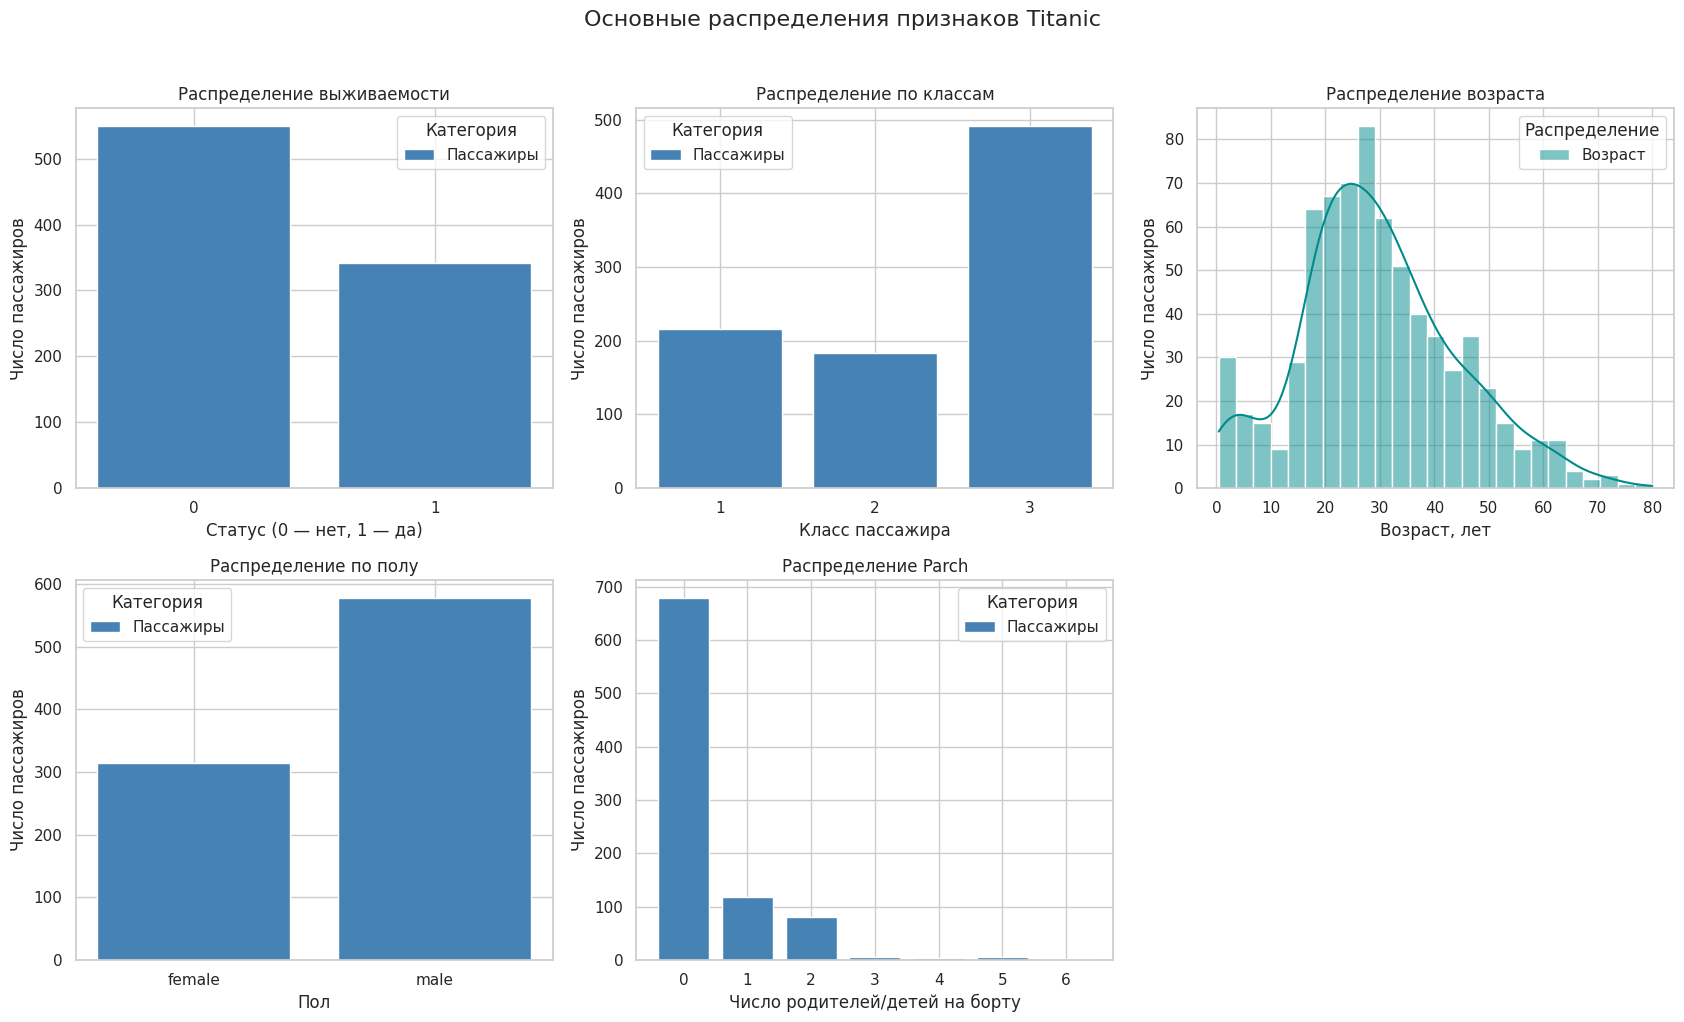

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.ravel()

# Для категориальных признаков строим столбчатые диаграммы частот.
category_specs = [
    ('Survived', 'Распределение выживаемости', 'Статус (0 — нет, 1 — да)', 'Число пассажиров'),
    ('Pclass', 'Распределение по классам', 'Класс пассажира', 'Число пассажиров'),
    ('Sex', 'Распределение по полу', 'Пол', 'Число пассажиров'),
    ('Parch', 'Распределение Parch', 'Число родителей/детей на борту', 'Число пассажиров'),
]
positions = [0, 1, 3, 4]
for (column, title, xlabel, ylabel), pos in zip(category_specs, positions):
    counts = df[column].value_counts(dropna=False).sort_index()
    axes[pos].bar(counts.index.astype(str), counts.values, color='steelblue', label='Пассажиры')
    axes[pos].set_title(title)
    axes[pos].set_xlabel(xlabel)
    axes[pos].set_ylabel(ylabel)
    axes[pos].legend(title='Категория')
    axes[pos].tick_params(axis='x', rotation=0)

# Для возраста строим гистограмму, пропуски автоматически исключаются.
sns.histplot(data=df, x='Age', bins=25, kde=True, ax=axes[2], color='darkcyan', label='Возраст')
axes[2].set_title('Распределение возраста')
axes[2].set_xlabel('Возраст, лет')
axes[2].set_ylabel('Число пассажиров')
axes[2].legend(title='Распределение')

# Удаляем пустую шестую панель.
fig.delaxes(axes[5])
fig.suptitle('Основные распределения признаков Titanic', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## 3. Boxplot для столбца `Age`

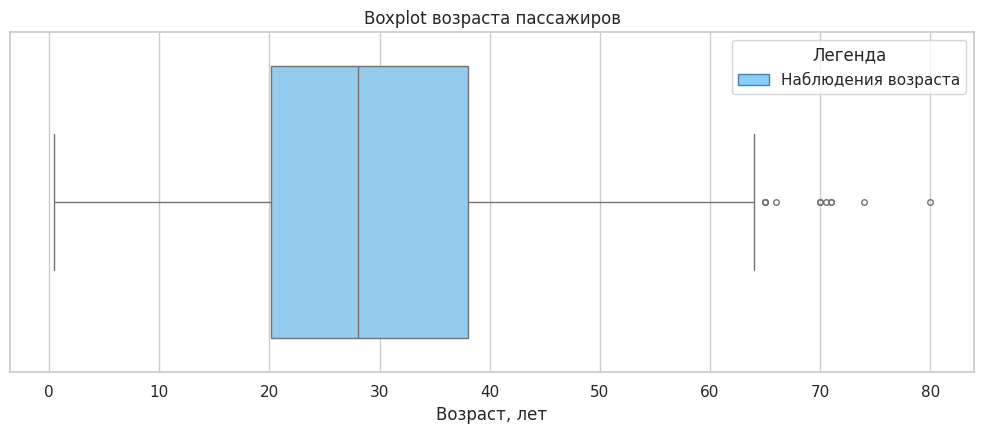

Число известных возрастов: 714 из 891
Медиана: 28.0; первый квартиль: 20.1; третий квартиль: 38.0.
Межквартильный размах IQR: 17.9.
Границы правила 1.5 × IQR: [-6.69; 64.81].
Значений возраста за этими границами: 11.

Интерпретация:
- Центральные 50% известных возрастов находятся примерно между 20.1 и 38.0 годами.
- Медианный возраст составляет 28.0 года; выбросами по правилу 1.5 × IQR отмечаются значения вне рассчитанных границ.
- Точки за пределами усов не обязательно являются ошибками: это могут быть реальные дети или пожилые пассажиры.


In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=df, x='Age', ax=ax, color='lightskyblue', flierprops={'marker': 'o', 'markersize': 4})
ax.set_title('Boxplot возраста пассажиров')
ax.set_xlabel('Возраст, лет')
ax.set_ylabel('')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor='lightskyblue', edgecolor='steelblue', label='Наблюдения возраста')], title='Легенда')
plt.tight_layout()
plt.show()

age = df['Age'].dropna()
q1, median, q3 = age.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outliers = age[(age < lower_bound) | (age > upper_bound)]
print(f'Число известных возрастов: {len(age)} из {len(df)}')
print(f'Медиана: {median:.1f}; первый квартиль: {q1:.1f}; третий квартиль: {q3:.1f}.')
print(f'Межквартильный размах IQR: {iqr:.1f}.')
print(f'Границы правила 1.5 × IQR: [{lower_bound:.2f}; {upper_bound:.2f}].')
print(f'Значений возраста за этими границами: {len(outliers)}.')

print('\nИнтерпретация:')
print(f'- Центральные 50% известных возрастов находятся примерно между {q1:.1f} и {q3:.1f} годами.')
print(f'- Медианный возраст составляет {median:.1f} года; выбросами по правилу 1.5 × IQR отмечаются значения вне рассчитанных границ.')
print('- Точки за пределами усов не обязательно являются ошибками: это могут быть реальные дети или пожилые пассажиры.')

## 4. Pie chart для `Survived` и `Pclass`

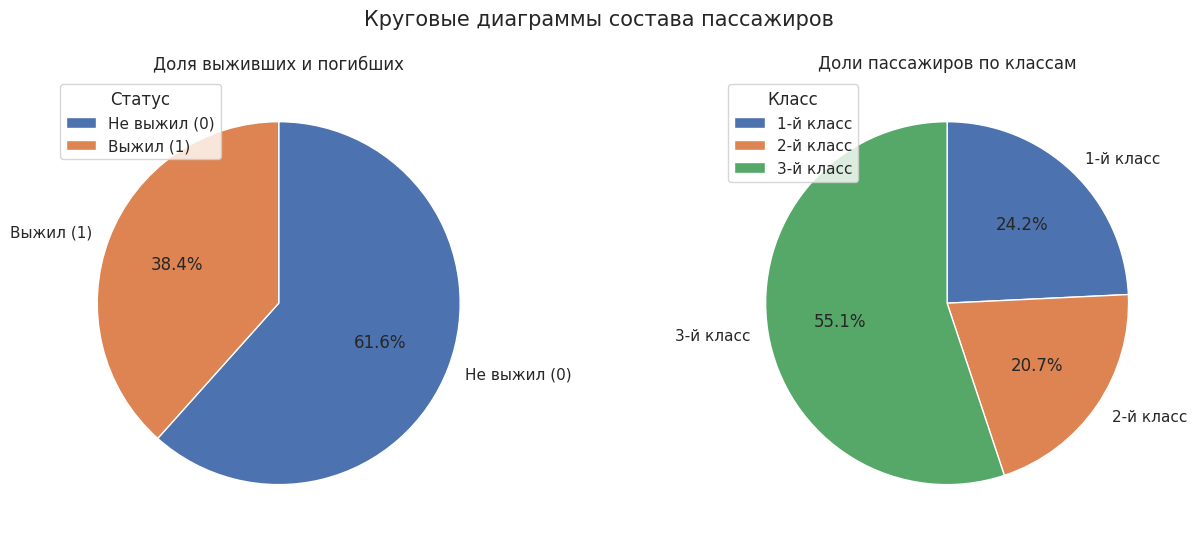

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

survived_counts = df['Survived'].value_counts().sort_index()
survived_labels = ['Не выжил (0)', 'Выжил (1)']
axes[0].pie(
    survived_counts.values, labels=survived_labels, autopct='%1.1f%%',
    startangle=90, counterclock=False, wedgeprops={'edgecolor': 'white'}
)
axes[0].set_title('Доля выживших и погибших')
axes[0].legend(survived_labels, title='Статус', loc='best')

class_counts = df['Pclass'].value_counts().sort_index()
class_labels = [f'{pclass}-й класс' for pclass in class_counts.index]
axes[1].pie(
    class_counts.values, labels=class_labels, autopct='%1.1f%%',
    startangle=90, counterclock=False, wedgeprops={'edgecolor': 'white'}
)
axes[1].set_title('Доли пассажиров по классам')
axes[1].legend(class_labels, title='Класс', loc='best')

fig.suptitle('Круговые диаграммы состава пассажиров', fontsize=15)
plt.tight_layout()
plt.show()

## 5. Pairplot для всех числовых признаков

Числовые признаки: ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']


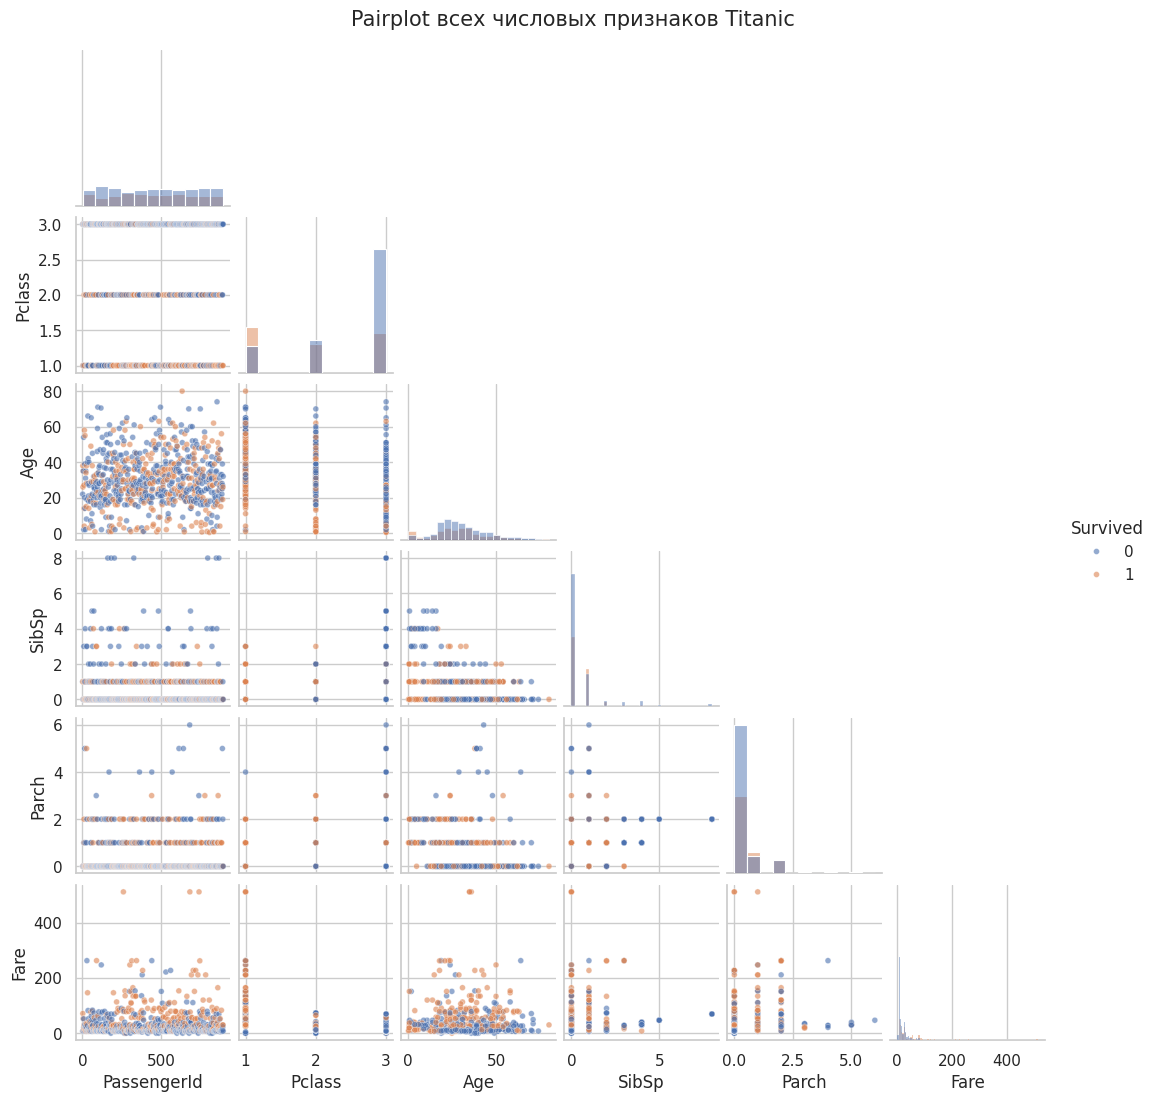

In [6]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
print('Числовые признаки:', numeric_columns)

# Используем hue=Survived, чтобы визуально сравнить числовые распределения групп выживших и погибших.
# Все числовые столбцы оставлены в матрице, включая сам Survived.
pair_data = df[numeric_columns].copy()
pair_plot = sns.pairplot(
    pair_data,
    hue='Survived' if 'Survived' in pair_data.columns else None,
    corner=True,
    diag_kind='hist',
    plot_kws={'alpha': 0.6, 's': 18},
    height=1.8,
)
pair_plot.fig.suptitle('Pairplot всех числовых признаков Titanic', y=1.02, fontsize=15)
plt.show()

## 6. Интерактивный sunburst: класс → пол

In [7]:
sunburst_data = (
    df.groupby(['Pclass', 'Sex'], observed=True)
      .size().rename('passengers').reset_index()
)
sunburst_data['Класс'] = sunburst_data['Pclass'].map(lambda value: f'{value}-й класс')
sunburst_data['Пол'] = sunburst_data['Sex'].map({'female': 'Женщины', 'male': 'Мужчины'}).fillna(sunburst_data['Sex'])

fig = px.sunburst(
    sunburst_data,
    path=['Класс', 'Пол'],
    values='passengers',
    color='Пол',
    title='Пассажиры по классам и полу',
    labels={'passengers': 'Число пассажиров', 'Класс': 'Класс', 'Пол': 'Пол'},
)
fig.update_traces(hovertemplate='<b>%{label}</b><br>Пассажиров: %{value}<br>Доля от общего числа: %{percentRoot:.1%}<extra></extra>')
fig.update_layout(margin=dict(t=70, l=20, r=20, b=20), legend_title_text='Пол')
fig.show()

## Вывод

In [8]:
print('Графики показывают распределение пассажиров по классу, полу, возрасту и семейным признакам.')
print('Boxplot даёт компактное представление о медиане, межквартильном размахе и потенциальных выбросах возраста.')
print('Sunburst позволяет интерактивно перейти от общего количества пассажиров к составу каждого класса по полу.')

Графики показывают распределение пассажиров по классу, полу, возрасту и семейным признакам.
Boxplot даёт компактное представление о медиане, межквартильном размахе и потенциальных выбросах возраста.
Sunburst позволяет интерактивно перейти от общего количества пассажиров к составу каждого класса по полу.
